<a href="https://colab.research.google.com/github/dtc-oss/python_hw/blob/hw_6/hw6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Задание 6. Бинарная классификация выживаемости Titanic
Датасет `train.csv` должен лежать рядом с ноутбуком.

**Целевая переменная:** `Survived` (0 — не выжил, 1 — выжил).

**Метрика:** основная метрика — F1-score для положительного класса (`Survived = 1`). Она объединяет precision и recall и подходит, когда важно одновременно не выдавать слишком много ложных прогнозов выживания и не пропускать слишком много выживших. Также показаны accuracy, precision, recall и ROC-AUC для для общей оценки правильности классификации и способности модели различать два класса при разных порогах классификации.

In [1]:
from pathlib import Path
import re
import warnings
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

# Фиксация случайности
RANDOM_STATE = 42

def find_data_file(filename: str) -> Path:
    """Ищет файл рядом с ноутбуком/в текущей папке и в стандартной папке задания."""
    candidates = [
        Path(filename),
        Path.cwd() / filename,
        Path.cwd().parent / filename,
    ]
    for path in candidates:
        if path.is_file():
            return path.resolve()
    searched = '\\n'.join(f' - {path}' for path in candidates)
    raise FileNotFoundError(
        f'Не найден файл {filename}. Поместите его рядом с ноутбуком. Проверены пути:\\n{searched}'
    )

from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')

## 1. Загрузка и подготовка датасета

In [2]:
data_path = find_data_file('train.csv')
df = pd.read_csv(data_path)
print(f'Размер исходного датасета: {df.shape}')
display(df.head())
print('Доля классов целевой переменной:')

# Баланс классов
class_counts = df['Survived'].value_counts().sort_index()
class_share = df['Survived'].value_counts(normalize=True).sort_index()

print('Баланс классов:')
print(f"  0 (погиб):  {class_counts[0]} чел.   {class_share[0] * 100:.1f}%")
print(f"  1 (выжил): {class_counts[1]} чел.   {class_share[1] * 100:.1f}%")

# Доля большинства для константного предсказания
majority_share = class_share.max()
print(f'\nДоля большинства: {majority_share:.4f}')

# Количество пропусков в признаках
print('\nПропуски в признаках:')
print(df[['Age', 'Cabin', 'Embarked']].isnull().sum().to_string())

# Используем признаки, известные для пассажира: класс, пол, возраст, размер семьи, тариф и порт посадки.
# PassengerId, Name, Ticket и Cabin не используются: они либо идентификаторы/текст, либо имеют много пропусков.
feature_columns = ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']
target_column = 'Survived'
X = df[feature_columns].copy()
y = df[target_column].astype(int).copy()

categorical_features = ['Pclass', 'Sex', 'Embarked']
numeric_features = ['Age', 'SibSp', 'Parch', 'Fare']

Размер исходного датасета: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


Доля классов целевой переменной:
Баланс классов:
  0 (погиб):  549 чел.   61.6%
  1 (выжил): 342 чел.   38.4%

Доля большинства: 0.6162

Пропуски в признаках:
Age         177
Cabin       687
Embarked      2


## 2. Разбиение на тренировочную и тестовую выборки

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y,
)
print(f'Размер train: {X_train.shape}; размер test: {X_test.shape}')

# Баланс классов в тестовой выборке
class_counts = y_test.value_counts().sort_index()
class_share = y_test.value_counts(normalize=True).sort_index()

print('Баланс классов в тестовой выборке:')
print(f"  0 (погиб):  {class_counts[0]} чел.   {class_share[0] * 100:.1f}%")
print(f"  1 (выжил): {class_counts[1]} чел.   {class_share[1] * 100:.1f}%")

# Доля большинства для константного предсказания
majority_share = class_share.max()
majority_class = class_counts.idxmax()

print(
    f'\nДоля большинства: {majority_share:.4f} '
    f'(класс {majority_class})'
)

Размер train: (712, 7); размер test: (179, 7)
Баланс классов в тестовой выборке:
  0 (погиб):  110 чел.   61.5%
  1 (выжил): 69 чел.   38.5%

Доля большинства: 0.6145 (класс 0)


## 3. Бейзлайн: всегда предсказывает наиболее частый класс.
Модель не предсказала ни одного выжившего пассажира. Поэтому Precision, Recall и F1-score для класса 1 равны нулю. Следующая модель должна улучшить качество распознавания выживших пассажиров, особенно по метрике F1-score.

In [4]:
baseline = DummyClassifier(strategy='most_frequent')
baseline.fit(X_train, y_train)
y_pred_baseline = baseline.predict(X_test)

baseline_results = {
    'model': 'DummyClassifier (most_frequent)',
    'accuracy': accuracy_score(y_test, y_pred_baseline),
    'precision': precision_score(y_test, y_pred_baseline, zero_division=0),
    'recall': recall_score(y_test, y_pred_baseline, zero_division=0),
    'f1': f1_score(y_test, y_pred_baseline, zero_division=0),
    'roc_auc': np.nan,  # У константного классификатора один класс прогноза, ROC-AUC здесь неинформативен.
}
display(pd.DataFrame([baseline_results]).set_index('model').round(4))

,accuracy,precision,recall,f1,roc_auc
model,,,,,
DummyClassifier (most_frequent),0.6145,0.0,0.0,0.0,NaN


## 4. Предобработка признаков и LogisticRegression

In [5]:
numeric_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
])
categorical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore')),
])
preprocessor = ColumnTransformer(transformers=[
    ('numeric', numeric_pipeline, numeric_features),
    ('categorical', categorical_pipeline, categorical_features),
])

model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
])
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

model_results = {
    'model': 'LogisticRegression',
    'accuracy': accuracy_score(y_test, y_pred),
    'precision': precision_score(y_test, y_pred, zero_division=0),
    'recall': recall_score(y_test, y_pred, zero_division=0),
    'f1': f1_score(y_test, y_pred, zero_division=0),
    'roc_auc': roc_auc_score(y_test, y_proba),
}

## 5. Сравнение качества на отложенной выборке

,accuracy,precision,recall,f1,roc_auc
model,,,,,
DummyClassifier (most_frequent),0.6145,0.0000,0.0000,0.0000,NaN
LogisticRegression,0.8045,0.7931,0.6667,0.7244,0.8427


Отчёт классификации для LogisticRegression:
              precision    recall  f1-score   support

Не выжил (0)       0.81      0.89      0.85       110
   Выжил (1)       0.79      0.67      0.72        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179



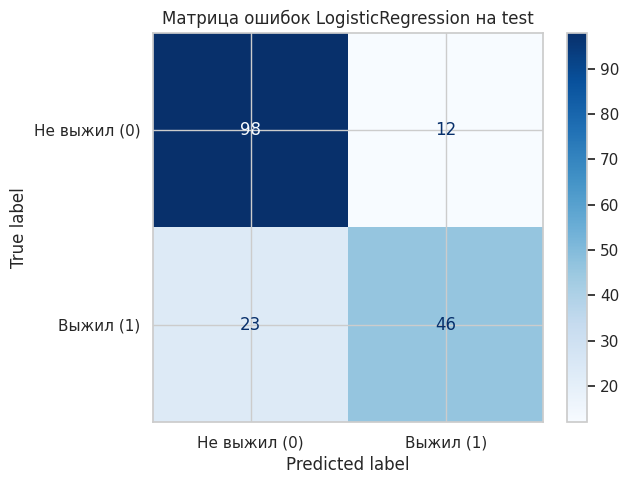

In [6]:
results = pd.DataFrame([baseline_results, model_results]).set_index('model')
display(results.round(4))

print('Отчёт классификации для LogisticRegression:')
print(classification_report(y_test, y_pred, target_names=['Не выжил (0)', 'Выжил (1)'], zero_division=0))

fig, ax = plt.subplots(figsize=(6.5, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=['Не выжил (0)', 'Выжил (1)'],
    cmap='Blues',
    values_format='d',
    ax=ax,
)
ax.set_title('Матрица ошибок LogisticRegression на test')
plt.tight_layout()
plt.show()

## 6. Вывод
LogisticRegression показала существенно лучшие результаты чем бейзлайн. Бейзлайн не обнаруживает ни одного выжившего, поэтому его нулевые Precision, Recall и F1-score показывают, почему одной Accuracy недостаточно для оценки качества классификатора.

In [7]:
print(f'Основная метрика F1 бейзлайна: {baseline_results["f1"]:.3f}')
print(f'Основная метрика F1 LogisticRegression: {model_results["f1"]:.3f}')
if model_results['f1'] > baseline_results['f1']:
    print('LogisticRegression улучшила F1 относительно константного бейзлайна на отложенной выборке.')
else:
    print('LogisticRegression не улучшила F1 относительно константного бейзлайна; стоит пересмотреть признаки/модель.')
print(f'Random state для воспроизводимости: {RANDOM_STATE}')

Основная метрика F1 бейзлайна: 0.000
Основная метрика F1 LogisticRegression: 0.724
LogisticRegression улучшила F1 относительно константного бейзлайна на отложенной выборке.
Random state для воспроизводимости: 42
